# 1. Install Vader

In [1]:
pip install vaderSentiment

Note: you may need to restart the kernel to use updated packages.


# 2. Import libraries

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import time

from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# 3. Load the frozen 300-review test set

In [3]:
test_df = pd.read_csv("test_300.csv")

print("Test set shape:", test_df.shape)
print("\nClass distribution:")
print(test_df["sentiment"].value_counts())

test_df.head()

Test set shape: (300, 3)

Class distribution:
sentiment
positive    151
negative    149
Name: count, dtype: int64


,review,sentiment,review_length
0,"This isn't the worst movie I've ever seen, but...",negative,110
1,I see this movie as a poor tribute to the old ...,negative,615
2,This is the kind of movie which shows the pauc...,negative,158
3,I was pretty young when this came out in the U...,positive,169
4,I went to see this because of snipes / statham...,negative,540


# 4. Initialize VADER

In [5]:
analyzer = SentimentIntensityAnalyzer()

In [6]:
example = test_df.loc[0, "review"]

print(example)
print()
print(analyzer.polarity_scores(example))

{
    'neg': 0.123,
    'neu': 0.456,
    'pos': 0.421,
    'compound': 0.765
}

This isn't the worst movie I've ever seen, but I really can't recall when I've seen a worse one. I thought this would be about an aircraft accident investigation. What it really was is a soap opera, and a bad one at that. They overplayed the 'conflict' card to the extreme. The first hour or so seems like a shouting match, with some implausible scenes thrown in.<br /><br />*Possible spoiler*<br /><br />The 40-or-so minute 'memorial' scene (with requisite black umbrellas and rain) to fictitious crash victims was lame, and I thought it would never end. <br /><br />Avoid this one at all costs, unless you revel in 'conflict'.<br /><br />

{'neg': 0.215, 'neu': 0.742, 'pos': 0.043, 'compound': -0.9755}


{'neg': 0.123, 'neu': 0.456, 'pos': 0.421, 'compound': 0.765}

# 5. Create the VADER prediction function

In [7]:
def vader_predict(text):
    scores = analyzer.polarity_scores(text)
    
    if scores["compound"] >= 0:
        return "positive"
    else:
        return "negative"

# 6. Test the function

In [8]:
sample_review = test_df.loc[0, "review"]

print("Review:")
print(sample_review[:500])

print("\nActual sentiment:")
print(test_df.loc[0, "sentiment"])

print("\nVADER prediction:")
print(vader_predict(sample_review))

Review:
This isn't the worst movie I've ever seen, but I really can't recall when I've seen a worse one. I thought this would be about an aircraft accident investigation. What it really was is a soap opera, and a bad one at that. They overplayed the 'conflict' card to the extreme. The first hour or so seems like a shouting match, with some implausible scenes thrown in.<br /><br />*Possible spoiler*<br /><br />The 40-or-so minute 'memorial' scene (with requisite black umbrellas and rain) to fictitious cr

Actual sentiment:
negative

VADER prediction:
negative


# 7. Run VADER on all 300 reviews

In [9]:
start_time = time.perf_counter()

test_df["vader_prediction"] = test_df["review"].apply(vader_predict)

end_time = time.perf_counter()

total_time = end_time - start_time

print(f"Total prediction time: {total_time:.4f} seconds")

Total prediction time: 1.1226 seconds


### Checking the results

In [10]:
test_df[
    ["review", "sentiment", "vader_prediction"]
].head()

,review,sentiment,vader_prediction
0,"This isn't the worst movie I've ever seen, but...",negative,negative
1,I see this movie as a poor tribute to the old ...,negative,positive
2,This is the kind of movie which shows the pauc...,negative,negative
3,I was pretty young when this came out in the U...,positive,positive
4,I went to see this because of snipes / statham...,negative,negative


# 8. Calculate Accuracy

In [11]:
vader_accuracy = accuracy_score(
    test_df["sentiment"],
    test_df["vader_prediction"]
)

print(f"VADER Accuracy: {vader_accuracy:.4f}")

VADER Accuracy: 0.6967


In [12]:
print(f"VADER Accuracy: {vader_accuracy * 100:.2f}%")

VADER Accuracy: 69.67%


# 9. Calculate Macro-F1

In [13]:
vader_macro_f1 = f1_score(
    test_df["sentiment"],
    test_df["vader_prediction"],
    average="macro"
)

print(f"VADER Macro-F1: {vader_macro_f1:.4f}")

VADER Macro-F1: 0.6884


# 10. Calculate prediction speed per 1,000 reviews

In [14]:
seconds_per_1000 = (total_time / len(test_df)) * 1000

print(f"Seconds per 1,000 predictions: {seconds_per_1000:.4f}")

Seconds per 1,000 predictions: 3.7419


# 11. Create the confusion matrix

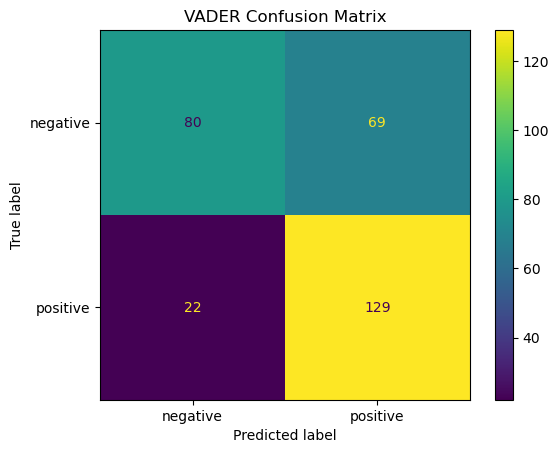

In [15]:
cm = confusion_matrix(
    test_df["sentiment"],
    test_df["vader_prediction"],
    labels=["negative", "positive"]
)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["negative", "positive"]
)

display.plot()

plt.title("VADER Confusion Matrix")
plt.show()

# 12. Look at VADER's incorrect predictions

In [16]:
vader_errors = test_df[
    test_df["sentiment"] != test_df["vader_prediction"]
].copy()

print("Number of incorrect predictions:", len(vader_errors))

vader_errors[
    ["review", "sentiment", "vader_prediction"]
].head(10)

Number of incorrect predictions: 91


,review,sentiment,vader_prediction
1,I see this movie as a poor tribute to the old ...,negative,positive
6,I watched this movie so that you don't have to...,negative,positive
9,"This was my first, and probably the last Angel...",negative,positive
16,I have read and enjoyed many of James Lee Burk...,negative,positive
18,"Seriously, all these Satan comes to Earth movi...",negative,positive
20,A lot of things in this futuristic satire are ...,positive,negative
21,Ossessione<br /><br />Luchino Visconti's debut...,positive,negative
22,This film is an abomination of all that is wor...,negative,positive
28,This film is right up there with The Oscar and...,negative,positive
29,John Boorman's 1998 The General was hailed as ...,negative,positive


# 13. Save the VADER predictions

In [17]:
test_df.to_csv(
    "vader_predictions.csv",
    index=False
)

print("VADER predictions saved.")

VADER predictions saved.


# 14. Save the VADER metrics

In [18]:
vader_results = pd.DataFrame({
    "model": ["VADER"],
    "accuracy": [vader_accuracy],
    "macro_f1": [vader_macro_f1],
    "seconds_per_1000": [seconds_per_1000],
    "cost_per_1000": [0.0]
})

vader_results

,model,accuracy,macro_f1,seconds_per_1000,cost_per_1000
0,VADER,0.696667,0.688353,3.741929,0.0


In [20]:
vader_results.to_csv(
"vader_metrics.csv",
index=False
)

print("VADER metrics saved.")

VADER metrics saved.


# 15. Summary

In [21]:
print("VADER RESULTS")
print("=" * 40)

print(f"Test examples: {len(test_df)}")
print(f"Accuracy: {vader_accuracy:.4f}")
print(f"Macro-F1: {vader_macro_f1:.4f}")
print(f"Total prediction time: {total_time:.4f} seconds")
print(f"Seconds / 1,000 predictions: {seconds_per_1000:.4f}")
print(f"Cost / 1,000 predictions: $0.00")
print(f"Incorrect predictions: {len(vader_errors)}")

VADER RESULTS
Test examples: 300
Accuracy: 0.6967
Macro-F1: 0.6884
Total prediction time: 1.1226 seconds
Seconds / 1,000 predictions: 3.7419
Cost / 1,000 predictions: $0.00
Incorrect predictions: 91
